# Figure 3c. Biomarker-QTL recall and enrichment of trans-eGene and trans-eProgram loci

For each biomarker family (protein, metabolite and glycoprotein QTL), recall is the fraction of biomarker-QTL loci that colocalize with a trans-eGene (circles) or trans-eProgram (squares) locus, and enrichment is the fraction of trans loci that colocalize with the biomarker family divided by the same fraction in the baseline set of all fine-mapped trans loci (dashed line = 1). Error bars are 95% confidence intervals, estimate ± 1.96 × leave-one-chromosome-out jackknife SE (22 autosomes), in both directions.

Input: `data/Figure_3c_biomarker_recall_enrichment.rds`

In [1]:
library(ggplot2)
res <- readRDS("data/Figure_3c_biomarker_recall_enrichment.rds")
res

method,biomarker,n_method_loci,n_biomarker_loci,n_overlap,n_baseline_loci,n_baseline_overlap,recall,recall_se,recall_ci_low,recall_ci_high,enrichment,enrichment_se,enrichment_ci_low,enrichment_ci_high
<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
trans-eGene,Protein QTL,94679,11903,2411,118897,2929,0.20255398,0.004637907,0.19346368,0.21164428,1.033701,0.009772985,1.0145463,1.052856
trans-eGene,Metabolite QTL,94679,1410,257,118897,319,0.18226950,0.009435966,0.16377501,0.20076400,1.011718,0.019600280,0.9733019,1.050135
trans-eGene,Glycoprotein QTL,94679,21325,3437,118897,4170,0.16117233,0.002926462,0.15543647,0.16690820,1.035049,0.007967749,1.0194317,1.050665
trans-eProgram,Protein QTL,38367,11903,1327,118897,2929,0.11148450,0.003284395,0.10504709,0.11792191,1.403992,0.049534776,1.3069038,1.501080
trans-eProgram,Metabolite QTL,38367,1410,143,118897,319,0.10141844,0.005515964,0.09060715,0.11222973,1.389180,0.078259176,1.2357917,1.542568
trans-eProgram,Glycoprotein QTL,38367,21325,1810,118897,4170,0.08487691,0.001454098,0.08202687,0.08772694,1.345103,0.041109166,1.2645291,1.425677


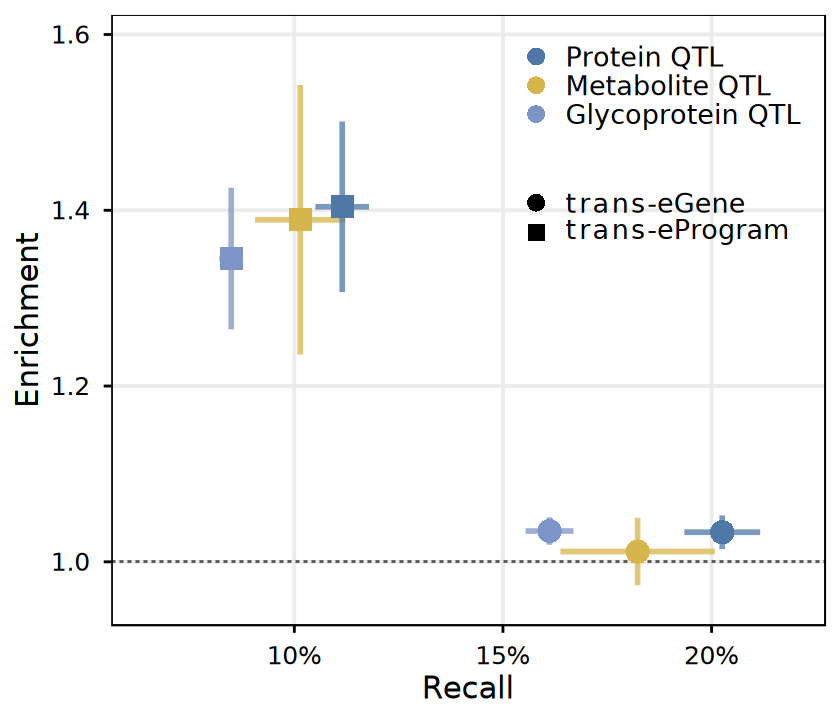

In [2]:
res$biomarker <- factor(res$biomarker, levels = c("Protein QTL", "Metabolite QTL", "Glycoprotein QTL"))
res$method    <- factor(res$method, levels = c("trans-eGene", "trans-eProgram"))

biomarker_colors <- c("Protein QTL" = "#4E79A7", "Metabolite QTL" = "#D6B64A", "Glycoprotein QTL" = "#7D94C6")
method_shapes    <- c("trans-eGene" = 16, "trans-eProgram" = 15)
method_labels    <- parse(text = c("italic(trans)*'-eGene'", "italic(trans)*'-eProgram'"))

p <- ggplot(res, aes(x = recall, y = enrichment, shape = method, colour = biomarker)) +
  geom_hline(yintercept = 1, linetype = "dashed", linewidth = 0.6, colour = "grey35") +
  geom_errorbar(aes(xmin = recall_ci_low, xmax = recall_ci_high), orientation = "y",
                width = 0, linewidth = 1.2, alpha = 0.75, show.legend = FALSE) +
  geom_errorbar(aes(ymin = enrichment_ci_low, ymax = enrichment_ci_high),
                width = 0, linewidth = 1.2, alpha = 0.75, show.legend = FALSE) +
  geom_point(size = 6) +
  scale_shape_manual(values = method_shapes, labels = method_labels) +
  scale_colour_manual(values = biomarker_colors) +
  scale_x_continuous(labels = function(x) paste0(round(100 * x, 1), "%"),
                     expand = expansion(mult = c(0.20, 0.12))) +
  scale_y_continuous(expand = expansion(mult = c(0.08, 0.14))) +
  guides(colour = guide_legend(order = 1, override.aes = list(shape = 16, size = 4.2)),
         shape  = guide_legend(order = 2, override.aes = list(colour = "black", size = 4.2))) +
  labs(x = "Recall", y = "Enrichment") +
  theme_minimal(base_size = 18) +
  theme(axis.text = element_text(colour = "black"),
        panel.grid.minor = element_blank(),
        panel.border = element_rect(colour = "black", fill = NA, linewidth = 0.6),
        axis.ticks = element_line(linewidth = 0.6, colour = "black"),
        legend.title = element_blank(), legend.text = element_text(size = 16),
        legend.position = "inside", legend.position.inside = c(0.98, 0.98),
        legend.justification = c(1, 1), legend.box.just = "left")

options(repr.plot.width = 7, repr.plot.height = 6)
p